In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# ============================================================
# KUTSENKO ML + FORECASTING PROJECT
# STEP 1 — LOAD 2019 CATALOGUE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATA_2019 = (
    "/kaggle/input/datasets/sj3267/kutsenko/"
    "KUTSENKO_2019_423_AR_clean.csv"
)

df19 = pd.read_csv(DATA_2019)

print("=" * 70)
print("KUTSENKO 2019 CATALOGUE")
print("=" * 70)

print("Shape:", df19.shape)

print("\nColumns:")
for i, col in enumerate(df19.columns):
    print(f"{i:2d}  {col}")

print("\nFirst 5 rows:")
display(df19.head())

KUTSENKO 2019 CATALOGUE
Shape: (423, 18)

Columns:
 0  catalogue_no
 1  HARP
 2  Phi_max_1e21_Mx
 3  R_av_1e20_Mx_per_h
 4  Stonyhurst_latitude_deg
 5  emergence_longitude_deg
 6  peak_flux_longitude_deg
 7  alpha_av_1e-8_m^-1
 8  polarity_separation_deg
 9  tilt_deg
10  emergence_onset
11  peak_flux_time
12  study
13  doi
14  emergence_onset_datetime
15  peak_flux_datetime
16  emergence_duration_h
17  R_av_reconstructed_1e20_Mx_per_h

First 5 rows:


,catalogue_no,HARP,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,Stonyhurst_latitude_deg,emergence_longitude_deg,peak_flux_longitude_deg,alpha_av_1e-8_m^-1,polarity_separation_deg,tilt_deg,emergence_onset,peak_flux_time,study,doi,emergence_onset_datetime,peak_flux_datetime,emergence_duration_h,R_av_reconstructed_1e20_Mx_per_h
0,1,10,1.86,2.70,-26.27,-20.10,-11.28,-2.1221,2.3684,0.2355,20100502_1936,20100503_1212,Kutsenko_2019,10.1093/mnras/stz308,2010-05-02 19:36:00,2010-05-03 12:12:00,16.6,1.120482
1,2,14,0.70,1.83,20.43,-5.78,-0.54,-1.8471,1.6455,-2.8077,20100504_2036,20100505_0548,Kutsenko_2019,10.1093/mnras/stz308,2010-05-04 20:36:00,2010-05-05 05:48:00,9.2,0.760870
2,3,17,0.74,0.43,-21.27,1.24,23.60,-1.2784,2.0053,0.5022,20100505_1912,20100507_1224,Kutsenko_2019,10.1093/mnras/stz308,2010-05-05 19:12:00,2010-05-07 12:24:00,41.2,0.179612
3,4,26,6.64,2.59,-15.25,-36.85,-2.07,-1.3820,3.9551,0.1471,20100520_1336,20100523_0300,Kutsenko_2019,10.1093/mnras/stz308,2010-05-20 13:36:00,2010-05-23 03:00:00,61.4,1.081433
4,5,40,1.69,0.67,-19.70,-34.71,-0.03,0.0134,2.0929,0.3296,20100527_0548,20100529_1836,Kutsenko_2019,10.1093/mnras/stz308,2010-05-27 05:48:00,2010-05-29 18:36:00,60.8,0.277961


In [3]:
# ============================================================
# DATA QUALITY AUDIT
# ============================================================

audit = pd.DataFrame({
    "dtype": df19.dtypes.astype(str),
    "missing": df19.isna().sum(),
    "unique": df19.nunique()
})

display(audit)

,dtype,missing,unique
catalogue_no,int64,0,423
HARP,int64,0,406
Phi_max_1e21_Mx,float64,0,306
R_av_1e20_Mx_per_h,float64,0,248
Stonyhurst_latitude_deg,float64,0,402
emergence_longitude_deg,float64,0,414
peak_flux_longitude_deg,float64,0,412
alpha_av_1e-8_m^-1,float64,0,420
polarity_separation_deg,float64,0,422
tilt_deg,float64,0,417


In [4]:
print("Duplicate rows:", df19.duplicated().sum())

print(
    "Unique HARPs:",
    df19["HARP"].nunique()
)

print(
    "Rows:",
    len(df19)
)

Duplicate rows: 0
Unique HARPs: 406
Rows: 423


In [5]:
# ============================================================
# STANDARDIZE HARP IDENTIFIER
# ============================================================

df19["HARP"] = (
    pd.to_numeric(
        df19["HARP"],
        errors="coerce"
    )
    .astype("Int64")
)

print(
    "Unique valid HARPs:",
    df19["HARP"].nunique()
)

print(
    "Missing HARP:",
    df19["HARP"].isna().sum()
)

Unique valid HARPs: 406
Missing HARP: 0


In [6]:
# ============================================================
# CORE KUTSENKO VARIABLES
# ============================================================

core_variables = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "Stonyhurst_latitude_deg",
    "emergence_longitude_deg",
    "peak_flux_longitude_deg",
    "alpha_av_1e-8_m^-1",
    "polarity_separation_deg",
    "tilt_deg",
    "emergence_duration_h",
]

print("Available core variables:\n")

for col in core_variables:
    print(
        f"{col:35s}",
        col in df19.columns
    )

Available core variables:

Phi_max_1e21_Mx                     True
R_av_1e20_Mx_per_h                  True
Stonyhurst_latitude_deg             True
emergence_longitude_deg             True
peak_flux_longitude_deg             True
alpha_av_1e-8_m^-1                  True
polarity_separation_deg             True
tilt_deg                            True
emergence_duration_h                True


In [7]:
# ============================================================
# ML DATASET
# ============================================================

ml19 = df19[
    [
        "HARP",
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "Stonyhurst_latitude_deg",
        "emergence_longitude_deg",
        "peak_flux_longitude_deg",
        "alpha_av_1e-8_m^-1",
        "polarity_separation_deg",
        "tilt_deg",
        "emergence_duration_h",
    ]
].copy()

print(
    "ML dataframe shape:",
    ml19.shape
)

display(ml19.head())

ML dataframe shape: (423, 10)


,HARP,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,Stonyhurst_latitude_deg,emergence_longitude_deg,peak_flux_longitude_deg,alpha_av_1e-8_m^-1,polarity_separation_deg,tilt_deg,emergence_duration_h
0,10,1.86,2.70,-26.27,-20.10,-11.28,-2.1221,2.3684,0.2355,16.6
1,14,0.70,1.83,20.43,-5.78,-0.54,-1.8471,1.6455,-2.8077,9.2
2,17,0.74,0.43,-21.27,1.24,23.60,-1.2784,2.0053,0.5022,41.2
3,26,6.64,2.59,-15.25,-36.85,-2.07,-1.3820,3.9551,0.1471,61.4
4,40,1.69,0.67,-19.70,-34.71,-0.03,0.0134,2.0929,0.3296,60.8


In [8]:
# ============================================================
# NUMERIC CLEANING
# ============================================================

numeric_features = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "Stonyhurst_latitude_deg",
    "emergence_longitude_deg",
    "peak_flux_longitude_deg",
    "alpha_av_1e-8_m^-1",
    "polarity_separation_deg",
    "tilt_deg",
    "emergence_duration_h",
]

for col in numeric_features:
    ml19[col] = pd.to_numeric(
        ml19[col],
        errors="coerce"
    )

ml19 = ml19.replace(
    [np.inf, -np.inf],
    np.nan
)

display(
    ml19[numeric_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Phi_max_1e21_Mx,423.0,3.900686,4.114774,0.3600,1.15500,2.4100,5.17500,25.2600
R_av_1e20_Mx_per_h,423.0,1.953191,1.303434,0.2400,0.97000,1.6300,2.55000,8.1300
Stonyhurst_latitude_deg,423.0,-0.129078,16.528390,-41.0400,-15.85500,4.8000,13.25500,40.7700
emergence_longitude_deg,423.0,-14.638534,25.087998,-59.2500,-35.06500,-16.5900,3.94000,43.6200
peak_flux_longitude_deg,423.0,10.801891,23.918884,-46.0600,-7.95000,10.1400,29.17000,57.5500
alpha_av_1e-8_m^-1,423.0,-0.188263,1.776652,-6.4379,-1.07920,-0.2433,0.75635,8.7670
polarity_separation_deg,423.0,3.091293,1.263434,0.7076,2.13215,2.8679,3.85770,8.1753
tilt_deg,423.0,0.526701,2.097262,-3.1414,-0.16035,0.2571,2.82680,3.1413
emergence_duration_h,423.0,45.054374,27.801118,5.2000,24.20000,37.4000,60.80000,150.6000


In [9]:
# ============================================================
# KUTSENKO SCALING
# Rav ~ Phi_max^kappa
# ============================================================

scaling_data = ml19[
    [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h"
    ]
].dropna().copy()

scaling_data = scaling_data[
    (scaling_data["Phi_max_1e21_Mx"] > 0)
    &
    (scaling_data["R_av_1e20_Mx_per_h"] > 0)
]

x = np.log10(
    scaling_data["Phi_max_1e21_Mx"]
)

y = np.log10(
    scaling_data["R_av_1e20_Mx_per_h"]
)

slope, intercept = np.polyfit(
    x,
    y,
    1
)

print(
    f"kappa = {slope:.4f}"
)

print(
    f"log10(A) = {intercept:.4f}"
)

print(
    f"A = {10**intercept:.4f}"
)

kappa = 0.4811
log10(A) = 0.0161
A = 1.0377


In [10]:
from scipy.stats import pearsonr, spearmanr

y_fit = intercept + slope * x

r2 = 1 - (
    np.sum((y - y_fit)**2)
    /
    np.sum((y - y.mean())**2)
)

pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)

print(f"R²             = {r2:.4f}")
print(f"Pearson r      = {pearson_r:.4f}")
print(f"Pearson p      = {pearson_p:.4e}")
print(f"Spearman rho   = {spearman_r:.4f}")
print(f"Spearman p     = {spearman_p:.4e}")

R²             = 0.5328
Pearson r      = 0.7299
Pearson p      = 1.4565e-71
Spearman rho   = 0.7245
Spearman p     = 4.9009e-70


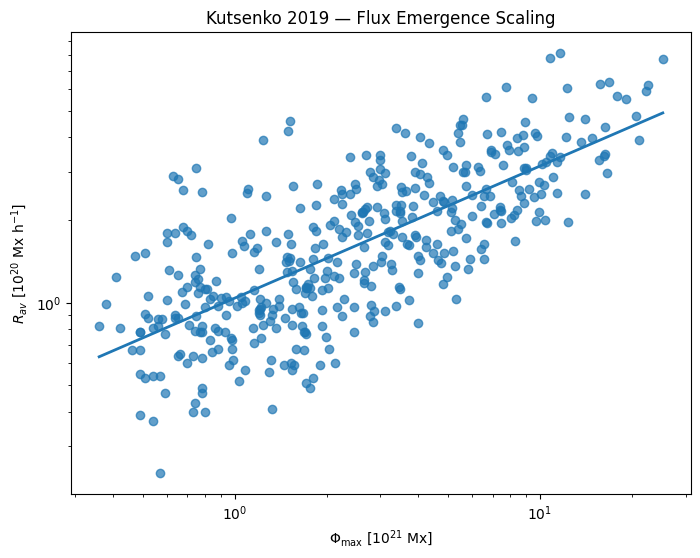

In [11]:
# ============================================================
# R_av vs Phi_max
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    scaling_data["Phi_max_1e21_Mx"],
    scaling_data["R_av_1e20_Mx_per_h"],
    alpha=0.7
)

phi_grid = np.logspace(
    np.log10(
        scaling_data["Phi_max_1e21_Mx"].min()
    ),
    np.log10(
        scaling_data["Phi_max_1e21_Mx"].max()
    ),
    200
)

rav_grid = (
    10**intercept
    *
    phi_grid**slope
)

plt.plot(
    phi_grid,
    rav_grid,
    linewidth=2
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    r"$\Phi_{\max}$ [$10^{21}$ Mx]"
)

plt.ylabel(
    r"$R_{av}$ [$10^{20}$ Mx h$^{-1}$]"
)

plt.title(
    "Kutsenko 2019 — Flux Emergence Scaling"
)

plt.show()

In [12]:
# ============================================================
# POLARITY SEPARATION SCALING
# ============================================================

sep_data = ml19[
    [
        "Phi_max_1e21_Mx",
        "polarity_separation_deg"
    ]
].dropna()

sep_data = sep_data[
    (sep_data["Phi_max_1e21_Mx"] > 0)
    &
    (sep_data["polarity_separation_deg"] > 0)
]

x_sep = np.log10(
    sep_data["Phi_max_1e21_Mx"]
)

y_sep = np.log10(
    sep_data["polarity_separation_deg"]
)

alpha_sep, intercept_sep = np.polyfit(
    x_sep,
    y_sep,
    1
)

print(
    f"Separation exponent = {alpha_sep:.4f}"
)

Separation exponent = 0.3616


In [13]:
# ============================================================
# NORMALIZED EMERGENCE RATE
# ============================================================

KAPPA_REFERENCE = 0.5

ml19["R_n"] = (
    ml19["R_av_1e20_Mx_per_h"]
    /
    ml19["Phi_max_1e21_Mx"]**KAPPA_REFERENCE
)

display(
    ml19[
        [
            "HARP",
            "Phi_max_1e21_Mx",
            "R_av_1e20_Mx_per_h",
            "R_n"
        ]
    ].head(10)
)

,HARP,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,R_n
0,10,1.86,2.70,1.979736
1,14,0.70,1.83,2.187268
2,17,0.74,0.43,0.499865
3,26,6.64,2.59,1.005115
4,40,1.69,0.67,0.515385
5,43,7.42,2.17,0.796632
6,44,0.94,1.05,1.082992
7,46,6.92,3.54,1.345706
8,47,0.76,1.08,1.238845
9,49,1.30,0.56,0.491152


In [14]:
# ============================================================
# CORRELATIONS WITH NORMALIZED EMERGENCE
# ============================================================

rn_features = [
    "Phi_max_1e21_Mx",
    "Stonyhurst_latitude_deg",
    "alpha_av_1e-8_m^-1",
    "polarity_separation_deg",
    "tilt_deg",
    "emergence_duration_h",
]

corr_results = []

for col in rn_features:

    temp = ml19[
        [col, "R_n"]
    ].dropna()

    if len(temp) >= 5:

        r, p = spearmanr(
            temp[col],
            temp["R_n"]
        )

        corr_results.append({
            "feature": col,
            "N": len(temp),
            "spearman_rho": r,
            "p_value": p
        })

rn_corr = pd.DataFrame(
    corr_results
).sort_values(
    "p_value"
)

display(rn_corr)

,feature,N,spearman_rho,p_value
5,emergence_duration_h,423,-0.646127,2.375698e-51
3,polarity_separation_deg,423,-0.152974,1.602262e-03
4,tilt_deg,423,-0.056481,2.464056e-01
0,Phi_max_1e21_Mx,423,-0.029436,5.460062e-01
1,Stonyhurst_latitude_deg,423,0.015828,7.454955e-01
2,alpha_av_1e-8_m^-1,423,-0.007085,8.844892e-01


In [15]:
print("Rows:", len(df19))
print("Unique HARPs:", df19["HARP"].nunique())

print("\nKappa:")
print(slope)

print("\nSeparation exponent:")
print(alpha_sep)

display(rn_corr)

Rows: 423
Unique HARPs: 406

Kappa:
0.48113767141415875

Separation exponent:
0.3615895588171711


,feature,N,spearman_rho,p_value
5,emergence_duration_h,423,-0.646127,2.375698e-51
3,polarity_separation_deg,423,-0.152974,1.602262e-03
4,tilt_deg,423,-0.056481,2.464056e-01
0,Phi_max_1e21_Mx,423,-0.029436,5.460062e-01
1,Stonyhurst_latitude_deg,423,0.015828,7.454955e-01
2,alpha_av_1e-8_m^-1,423,-0.007085,8.844892e-01


In [16]:
# ============================================================
# ML STAGE 1 — EMERGENCE RATE PREDICTION
# ============================================================

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

FEATURES = [
    "Phi_max_1e21_Mx",
    "Stonyhurst_latitude_deg",
    "emergence_longitude_deg",
    "peak_flux_longitude_deg",
    "alpha_av_1e-8_m^-1",
    "polarity_separation_deg",
    "tilt_deg",
    "emergence_duration_h"
]

TARGET = "R_av_1e20_Mx_per_h"

reg_data = ml19[
    FEATURES + [TARGET]
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna(
    subset=[TARGET]
)

print("Regression rows:", len(reg_data))
print("Features:", FEATURES)

Regression rows: 423
Features: ['Phi_max_1e21_Mx', 'Stonyhurst_latitude_deg', 'emergence_longitude_deg', 'peak_flux_longitude_deg', 'alpha_av_1e-8_m^-1', 'polarity_separation_deg', 'tilt_deg', 'emergence_duration_h']


In [17]:
X = reg_data[FEATURES]
y = reg_data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training:", len(X_train))
print("Testing :", len(X_test))

Training: 338
Testing : 85


In [18]:
# ============================================================
# PHYSICS BASELINE
# ============================================================

KAPPA = slope
A = 10**intercept

baseline_pred = (
    A
    *
    X_test["Phi_max_1e21_Mx"]**KAPPA
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_pred
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

print("KUTSENKO POWER-LAW BASELINE")
print("-" * 40)
print(f"MAE  : {baseline_mae:.5f}")
print(f"RMSE : {baseline_rmse:.5f}")
print(f"R²   : {baseline_r2:.5f}")

KUTSENKO POWER-LAW BASELINE
----------------------------------------
MAE  : 0.57455
RMSE : 0.78679
R²   : 0.59872


In [19]:
# ============================================================
# LINEAR ML
# ============================================================

linear_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

linear_model.fit(
    X_train,
    y_train
)

linear_pred = linear_model.predict(
    X_test
)

print("LINEAR REGRESSION")
print("-" * 40)
print(
    f"MAE  : "
    f"{mean_absolute_error(y_test, linear_pred):.5f}"
)
print(
    f"RMSE : "
    f"{np.sqrt(mean_squared_error(y_test, linear_pred)):.5f}"
)
print(
    f"R²   : "
    f"{r2_score(y_test, linear_pred):.5f}"
)

LINEAR REGRESSION
----------------------------------------
MAE  : 0.41122
RMSE : 0.51645
R²   : 0.82711


In [20]:
# ============================================================
# RANDOM FOREST
# ============================================================

rf_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=4,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

print("RANDOM FOREST")
print("-" * 40)
print(
    f"MAE  : "
    f"{mean_absolute_error(y_test, rf_pred):.5f}"
)
print(
    f"RMSE : "
    f"{np.sqrt(mean_squared_error(y_test, rf_pred)):.5f}"
)
print(
    f"R²   : "
    f"{r2_score(y_test, rf_pred):.5f}"
)

RANDOM FOREST
----------------------------------------
MAE  : 0.48652
RMSE : 0.65032
R²   : 0.72585


In [21]:
# ============================================================
# HISTOGRAM GRADIENT BOOSTING
# ============================================================

hgb_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.03,
            max_leaf_nodes=15,
            min_samples_leaf=8,
            l2_regularization=1.0,
            random_state=42
        )
    )
])

hgb_model.fit(
    X_train,
    y_train
)

hgb_pred = hgb_model.predict(
    X_test
)

print("GRADIENT BOOSTING")
print("-" * 40)
print(
    f"MAE  : "
    f"{mean_absolute_error(y_test, hgb_pred):.5f}"
)
print(
    f"RMSE : "
    f"{np.sqrt(mean_squared_error(y_test, hgb_pred)):.5f}"
)
print(
    f"R²   : "
    f"{r2_score(y_test, hgb_pred):.5f}"
)

GRADIENT BOOSTING
----------------------------------------
MAE  : 0.18228
RMSE : 0.34132
R²   : 0.92448


In [22]:
# ============================================================
# MODEL COMPARISON
# ============================================================

model_results = pd.DataFrame([
    {
        "Model": "Kutsenko power law",
        "MAE": mean_absolute_error(
            y_test,
            baseline_pred
        ),
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Linear regression",
        "MAE": mean_absolute_error(
            y_test,
            linear_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                linear_pred
            )
        ),
        "R2": r2_score(
            y_test,
            linear_pred
        )
    },
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(
            y_test,
            rf_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                rf_pred
            )
        ),
        "R2": r2_score(
            y_test,
            rf_pred
        )
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(
            y_test,
            hgb_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test,
                hgb_pred
            )
        ),
        "R2": r2_score(
            y_test,
            hgb_pred
        )
    }
])

display(
    model_results.sort_values(
        "RMSE"
    )
)

,Model,MAE,RMSE,R2
3,Gradient Boosting,0.182277,0.341316,0.924484
1,Linear regression,0.411222,0.516446,0.827109
2,Random Forest,0.486517,0.650323,0.725854
0,Kutsenko power law,0.574550,0.786792,0.598724


In [23]:
# ============================================================
# ABLATION — REMOVE EMERGENCE DURATION
# ============================================================

FEATURES_NO_DURATION = [
    col
    for col in FEATURES
    if col != "emergence_duration_h"
]

X2 = reg_data[
    FEATURES_NO_DURATION
]

y2 = reg_data[TARGET]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=42
)

rf_no_duration = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=4,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_no_duration.fit(
    X2_train,
    y2_train
)

pred_no_duration = rf_no_duration.predict(
    X2_test
)

print(
    "Random Forest WITHOUT emergence duration"
)

print(
    "RMSE:",
    np.sqrt(
        mean_squared_error(
            y2_test,
            pred_no_duration
        )
    )
)

print(
    "R²:",
    r2_score(
        y2_test,
        pred_no_duration
    )
)

Random Forest WITHOUT emergence duration
RMSE: 0.7756758469766513
R²: 0.609982330636666


In [24]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

rf_inner = rf_model.named_steps["model"]

importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": rf_inner.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(importance)

,feature,importance
0,Phi_max_1e21_Mx,0.442783
5,polarity_separation_deg,0.200603
7,emergence_duration_h,0.112375
2,emergence_longitude_deg,0.063623
3,peak_flux_longitude_deg,0.052100
4,alpha_av_1e-8_m^-1,0.050421
1,Stonyhurst_latitude_deg,0.041088
6,tilt_deg,0.037007


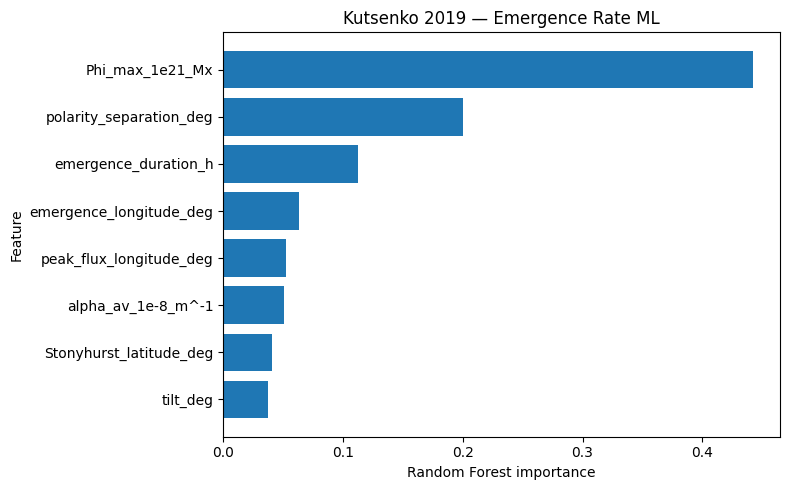

In [25]:
plt.figure(figsize=(8, 5))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel(
    "Random Forest importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Kutsenko 2019 — Emergence Rate ML"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [26]:
display(model_results)

print(
    "RF with duration:",
    r2_score(y_test, rf_pred)
)

print(
    "RF without duration:",
    r2_score(y2_test, pred_no_duration)
)

display(importance)

,Model,MAE,RMSE,R2
0,Kutsenko power law,0.574550,0.786792,0.598724
1,Linear regression,0.411222,0.516446,0.827109
2,Random Forest,0.486517,0.650323,0.725854
3,Gradient Boosting,0.182277,0.341316,0.924484


RF with duration: 0.7258542190084747
RF without duration: 0.609982330636666


,feature,importance
0,Phi_max_1e21_Mx,0.442783
5,polarity_separation_deg,0.200603
7,emergence_duration_h,0.112375
2,emergence_longitude_deg,0.063623
3,peak_flux_longitude_deg,0.052100
4,alpha_av_1e-8_m^-1,0.050421
1,Stonyhurst_latitude_deg,0.041088
6,tilt_deg,0.037007


In [27]:
# ============================================================
# CROSS-VALIDATION — KUTSENKO 2019
# ============================================================

from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Linear regression": linear_model,

    "Random Forest": rf_model,

    "Gradient Boosting": hgb_model
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,

        "R2_mean":
            scores["test_R2"].mean(),

        "R2_std":
            scores["test_R2"].std(),

        "MAE_mean":
            -scores["test_MAE"].mean(),

        "MAE_std":
            scores["test_MAE"].std(),

        "RMSE_mean":
            -scores["test_RMSE"].mean(),

        "RMSE_std":
            scores["test_RMSE"].std()
    })

cv_table = pd.DataFrame(cv_results)

display(
    cv_table.sort_values(
        "R2_mean",
        ascending=False
    )
)

,Model,R2_mean,R2_std,MAE_mean,MAE_std,RMSE_mean,RMSE_std
2,Gradient Boosting,0.916882,0.021417,0.189561,0.029480,0.373385,0.068443
0,Linear regression,0.793143,0.039158,0.429678,0.027399,0.587991,0.070113
1,Random Forest,0.641663,0.056963,0.532627,0.036371,0.775471,0.085494


In [28]:
# ============================================================
# REPEATED CV FOR GRADIENT BOOSTING
# ============================================================

from sklearn.model_selection import RepeatedKFold

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

gb_cv = cross_validate(
    hgb_model,
    X,
    y,
    cv=repeated_cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print(
    "Gradient Boosting"
)

print(
    "R²:",
    gb_cv["test_R2"].mean(),
    "±",
    gb_cv["test_R2"].std()
)

print(
    "MAE:",
    -gb_cv["test_MAE"].mean(),
    "±",
    gb_cv["test_MAE"].std()
)

print(
    "RMSE:",
    -gb_cv["test_RMSE"].mean(),
    "±",
    gb_cv["test_RMSE"].std()
)

Gradient Boosting
R²: 0.9173808053203543 ± 0.028053049461109484
MAE: 0.1941906404781287 ± 0.03439206808808488
RMSE: 0.36823407636399147 ± 0.08668177995945414


In [29]:
# ============================================================
# FEATURE ABLATION
# ============================================================

feature_sets = {

    "Phi only": [
        "Phi_max_1e21_Mx"
    ],

    "Phi + separation": [
        "Phi_max_1e21_Mx",
        "polarity_separation_deg"
    ],

    "Phi + separation + duration": [
        "Phi_max_1e21_Mx",
        "polarity_separation_deg",
        "emergence_duration_h"
    ],

    "All features": FEATURES
}

ablation_results = []

for name, feature_set in feature_sets.items():

    X_ab = reg_data[
        feature_set
    ]

    scores = cross_validate(
        hgb_model,
        X_ab,
        y,
        cv=cv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    ablation_results.append({
        "Model": name,
        "Features": len(feature_set),
        "R2": scores["test_R2"].mean(),
        "R2_std": scores["test_R2"].std(),
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean()
    })

ablation_table = pd.DataFrame(
    ablation_results
)

display(ablation_table)

,Model,Features,R2,R2_std,MAE,RMSE
0,Phi only,1,0.473380,0.093128,0.678084,0.937471
1,Phi + separation,2,0.464837,0.099251,0.681018,0.945013
2,Phi + separation + duration,3,0.931531,0.017978,0.172275,0.338975
3,All features,8,0.916882,0.021417,0.189561,0.373385


In [30]:
# ============================================================
# DOES EMERGENCE DURATION SIMPLY REFLECT FLUX/RATE?
# ============================================================

duration_test = ml19[
    [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "emergence_duration_h"
    ]
].dropna()

duration_test = duration_test[
    (duration_test["Phi_max_1e21_Mx"] > 0) &
    (duration_test["R_av_1e20_Mx_per_h"] > 0) &
    (duration_test["emergence_duration_h"] > 0)
].copy()

duration_test["flux_rate_times_duration"] = (
    duration_test["R_av_1e20_Mx_per_h"]
    *
    duration_test["emergence_duration_h"]
)

display(
    duration_test[
        [
            "Phi_max_1e21_Mx",
            "flux_rate_times_duration"
        ]
    ].corr(
        method="spearman"
    )
)

,Phi_max_1e21_Mx,flux_rate_times_duration
Phi_max_1e21_Mx,1.000000,0.999982
flux_rate_times_duration,0.999982,1.000000


In [31]:
# ============================================================
# KUTSENKO 2019 + 2021
# LOAD BOTH CATALOGUES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

KUTSENKO_DIR = Path(
    "/kaggle/input/datasets/sj3267/kutsenko"
)

print("=" * 70)
print("FILES IN KUTSENKO DATASET")
print("=" * 70)

for f in KUTSENKO_DIR.glob("*.csv"):
    print(f.name)

FILES IN KUTSENKO DATASET
KUTSENKO_2019_2021_common_HARP_index.csv
KUTSENKO_2021_243_AR_supplement_available.csv
KUTSENKO_2021_243_AR_model_ready.csv
KUTSENKO_2019_423_AR_clean.csv


In [32]:
# ============================================================
# LOAD DATASETS
# ============================================================

PATH_2019 = (
    KUTSENKO_DIR /
    "KUTSENKO_2019_423_AR_clean.csv"
)

PATH_2021 = (
    KUTSENKO_DIR /
    "KUTSENKO_2021_243_AR_model_ready.csv"
)

df19 = pd.read_csv(PATH_2019)
df21 = pd.read_csv(PATH_2021)

print("\n2019 catalogue:")
print(df19.shape)

print("\n2021 catalogue:")
print(df21.shape)


2019 catalogue:
(423, 18)

2021 catalogue:
(243, 16)


In [33]:
# ============================================================
# 2021 DATA AUDIT
# ============================================================

print("=" * 70)
print("KUTSENKO 2021 DATASET")
print("=" * 70)

print("\nColumns:")

for i, col in enumerate(df21.columns):
    print(
        f"{i:2d}  {col}"
    )

print("\nMissing values:")

display(
    df21.isna()
    .sum()
    .sort_values(
        ascending=False
    )
    .to_frame("missing")
)

KUTSENKO 2021 DATASET

Columns:
 0  HARP
 1  emergence_onset
 2  power_index_saturation_time
 3  peak_flux_time
 4  alpha_sat
 5  alpha_sat_std
 6  alpha_mean
 7  alpha_mean_std
 8  Phi_max_1e21_Mx
 9  Phi_max_uncertainty_1e21_Mx
10  R_av_1e20_Mx_per_h
11  R_av_uncertainty_1e20_Mx_per_h
12  flare_index
13  flare_productive_FI_ge_1
14  log10_Phi_max
15  log10_R_av

Missing values:


,missing
HARP,0
emergence_onset,0
power_index_saturation_time,0
peak_flux_time,0
alpha_sat,0
alpha_sat_std,0
alpha_mean,0
alpha_mean_std,0
Phi_max_1e21_Mx,0
Phi_max_uncertainty_1e21_Mx,0


In [34]:
print("\nShape:", df21.shape)

print(
    "Unique HARPs:",
    df21["HARP"].nunique()
)

print(
    "Flare productive:",
    df21[
        "flare_productive_FI_ge_1"
    ].value_counts(
        dropna=False
    )
)

print(
    "\nFlare index statistics:"
)

display(
    df21[
        "flare_index"
    ].describe()
)


Shape: (243, 16)
Unique HARPs: 235
Flare productive: flare_productive_FI_ge_1
0    209
1     34
Name: count, dtype: int64

Flare index statistics:


count    243.000000
mean       0.959730
std        3.830705
min        0.000000
25%        0.000000
50%        0.000000
75%        0.193050
max       41.463600
Name: flare_index, dtype: float64

In [35]:
# ============================================================
# HARP STANDARDIZATION
# ============================================================

df19["HARP"] = (
    pd.to_numeric(
        df19["HARP"],
        errors="coerce"
    )
    .astype("Int64")
)

df21["HARP"] = (
    pd.to_numeric(
        df21["HARP"],
        errors="coerce"
    )
    .astype("Int64")
)

print(
    "2019 unique HARPs:",
    df19["HARP"].nunique()
)

print(
    "2021 unique HARPs:",
    df21["HARP"].nunique()
)

2019 unique HARPs: 406
2021 unique HARPs: 235


In [36]:
# ============================================================
# KUTSENKO 2021 — FLARE PRODUCTIVITY
# R_av vs FLARE INDEX
# ============================================================

from scipy.stats import (
    pearsonr,
    spearmanr
)

flare_data = df21[
    [
        "HARP",
        "R_av_1e20_Mx_per_h",
        "Phi_max_1e21_Mx",
        "flare_index"
    ]
].copy()

flare_data = flare_data.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(
    subset=[
        "R_av_1e20_Mx_per_h",
        "flare_index"
    ]
)

flare_data = flare_data[
    flare_data[
        "R_av_1e20_Mx_per_h"
    ] > 0
]

print(
    "Usable ARs:",
    len(flare_data)
)

Usable ARs: 243


In [37]:
# ============================================================
# CORRELATION
# ============================================================

pearson_r, pearson_p = pearsonr(
    flare_data[
        "R_av_1e20_Mx_per_h"
    ],
    flare_data[
        "flare_index"
    ]
)

spearman_r, spearman_p = spearmanr(
    flare_data[
        "R_av_1e20_Mx_per_h"
    ],
    flare_data[
        "flare_index"
    ]
)

print("=" * 60)

print(
    f"Pearson r  = {pearson_r:.4f}"
)

print(
    f"Pearson p  = {pearson_p:.4e}"
)

print()

print(
    f"Spearman ρ = {spearman_r:.4f}"
)

print(
    f"Spearman p = {spearman_p:.4e}"
)

Pearson r  = 0.4742
Pearson p  = 5.0185e-15

Spearman ρ = 0.3805
Spearman p = 8.6570e-10


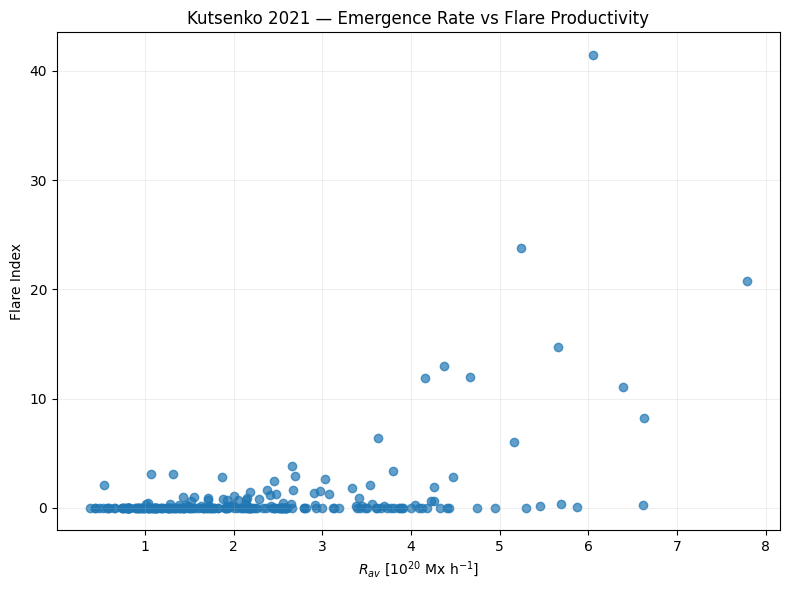

In [38]:
# ============================================================
# R_av vs FLARE INDEX
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    flare_data[
        "R_av_1e20_Mx_per_h"
    ],
    flare_data[
        "flare_index"
    ],
    alpha=0.7
)

plt.xlabel(
    r"$R_{av}$ [$10^{20}$ Mx h$^{-1}$]"
)

plt.ylabel(
    "Flare Index"
)

plt.title(
    "Kutsenko 2021 — Emergence Rate vs Flare Productivity"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()

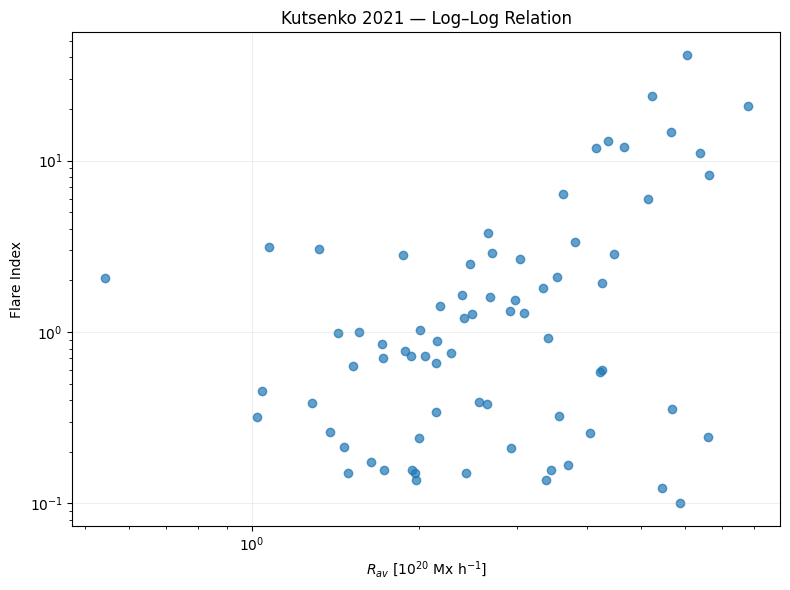

In [39]:
# ============================================================
# LOG-SCALE VERSION
# ============================================================

plot_data = flare_data[
    flare_data["flare_index"] > 0
].copy()

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    plot_data[
        "R_av_1e20_Mx_per_h"
    ],
    plot_data[
        "flare_index"
    ],
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    r"$R_{av}$ [$10^{20}$ Mx h$^{-1}$]"
)

plt.ylabel(
    "Flare Index"
)

plt.title(
    "Kutsenko 2021 — Log–Log Relation"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()

In [40]:
# ============================================================
# FLARE PRODUCTIVITY DISTRIBUTION
# ============================================================

print(
    df21[
        "flare_productive_FI_ge_1"
    ].value_counts()
)

productive = df21[
    df21[
        "flare_productive_FI_ge_1"
    ] == 1
].copy()

nonproductive = df21[
    df21[
        "flare_productive_FI_ge_1"
    ] == 0
].copy()

print(
    "\nProductive ARs:",
    len(productive)
)

print(
    "Non-productive ARs:",
    len(nonproductive)
)

flare_productive_FI_ge_1
0    209
1     34
Name: count, dtype: int64

Productive ARs: 34
Non-productive ARs: 209


In [41]:
# ============================================================
# PRODUCTIVE VS NON-PRODUCTIVE
# ============================================================

comparison = pd.DataFrame({
    "Flare productive": [
        productive[
            "R_av_1e20_Mx_per_h"
        ].median(),
        productive[
            "R_av_1e20_Mx_per_h"
        ].mean()
    ],

    "Not flare productive": [
        nonproductive[
            "R_av_1e20_Mx_per_h"
        ].median(),
        nonproductive[
            "R_av_1e20_Mx_per_h"
        ].mean()
    ]
}, index=[
    "Median R_av",
    "Mean R_av"
])

display(comparison)

,Flare productive,Not flare productive
Median R_av,3.056150,1.777700
Mean R_av,3.514203,2.062833


In [42]:
# ============================================================
# CORRELATION MATRIX — FLARE PRODUCTIVITY
# ============================================================

candidate_features = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "alpha_sat",
    "alpha_mean",
    "alpha_sat_std",
    "alpha_mean_std",
    "flare_index"
]

corr_data = df21[
    candidate_features
].apply(
    pd.to_numeric,
    errors="coerce"
)

display(
    corr_data.corr(
        method="spearman"
    )
)

,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,alpha_sat,alpha_mean,alpha_sat_std,alpha_mean_std,flare_index
Phi_max_1e21_Mx,1.000000,0.672144,-0.237331,-0.245485,-0.258428,0.049919,0.547598
R_av_1e20_Mx_per_h,0.672144,1.000000,-0.078246,0.076254,-0.211416,-0.280642,0.380461
alpha_sat,-0.237331,-0.078246,1.000000,0.682734,0.027834,-0.087353,-0.188891
alpha_mean,-0.245485,0.076254,0.682734,1.000000,0.059908,-0.300884,-0.113144
alpha_sat_std,-0.258428,-0.211416,0.027834,0.059908,1.000000,-0.004162,-0.160206
alpha_mean_std,0.049919,-0.280642,-0.087353,-0.300884,-0.004162,1.000000,0.030489
flare_index,0.547598,0.380461,-0.188891,-0.113144,-0.160206,0.030489,1.000000


In [43]:
display(
    corr_data.corr(
        method="pearson"
    )
)

,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,alpha_sat,alpha_mean,alpha_sat_std,alpha_mean_std,flare_index
Phi_max_1e21_Mx,1.000000,0.701355,-0.211321,-0.230048,-0.204654,-0.034613,0.622015
R_av_1e20_Mx_per_h,0.701355,1.000000,-0.059557,0.046640,-0.208770,-0.199777,0.474168
alpha_sat,-0.211321,-0.059557,1.000000,0.722300,0.065539,-0.086000,-0.156164
alpha_mean,-0.230048,0.046640,0.722300,1.000000,0.073134,-0.260604,-0.108223
alpha_sat_std,-0.204654,-0.208770,0.065539,0.073134,1.000000,0.039840,-0.083434
alpha_mean_std,-0.034613,-0.199777,-0.086000,-0.260604,0.039840,1.000000,-0.063556
flare_index,0.622015,0.474168,-0.156164,-0.108223,-0.083434,-0.063556,1.000000


In [44]:
TARGET_CLASS = (
    "flare_productive_FI_ge_1"
)

In [45]:
TARGET_REGRESSION = "flare_index"

In [46]:
# ============================================================
# FLARE CLASSIFICATION DATASET
# ============================================================

FLARE_FEATURES = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "alpha_sat",
    "alpha_mean",
    "alpha_sat_std",
    "alpha_mean_std"
]

classification_data = df21[
    FLARE_FEATURES +
    [
        "flare_productive_FI_ge_1"
    ]
].copy()

classification_data = (
    classification_data
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

print(
    "Classification dataset:",
    classification_data.shape
)

display(
    classification_data.head()
)

Classification dataset: (243, 7)


,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,alpha_sat,alpha_mean,alpha_sat_std,alpha_mean_std,flare_productive_FI_ge_1
0,0.7856,1.6658,2.4441,2.4484,0.0604,0.0527,0
1,0.8061,0.4331,1.8862,1.4202,0.0548,0.2785,0
2,6.8948,2.5311,2.4614,2.0209,0.0529,0.2865,0
3,7.5581,2.1895,1.5483,1.6684,0.1661,0.2971,0
4,1.3756,0.5429,1.5724,1.4592,0.0373,0.1973,1


In [47]:
# ============================================================
# CLASS BALANCE
# ============================================================

class_counts = (
    classification_data[
        "flare_productive_FI_ge_1"
    ]
    .value_counts()
    .sort_index()
)

display(
    class_counts
)

print(
    "Positive fraction:",
    class_counts.get(1, 0)
    /
    class_counts.sum()
)

flare_productive_FI_ge_1
0    209
1     34
Name: count, dtype: int64

Positive fraction: 0.13991769547325103


In [48]:
# ============================================================
# BASELINE: R_av ONLY
# ============================================================

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = classification_data[
    ["R_av_1e20_Mx_per_h"]
]

y = classification_data[
    "flare_productive_FI_ge_1"
]

cv_strat = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_logistic = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000
        )
    )
])

baseline_prob = cross_val_predict(
    baseline_logistic,
    X,
    y,
    cv=cv_strat,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [49]:
# ============================================================
# BASELINE METRICS
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

print(
    "R_av-only baseline"
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y,
        baseline_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y,
        baseline_prob
    )
)

print(
    "Brier score:",
    brier_score_loss(
        y,
        baseline_prob
    )
)

R_av-only baseline
ROC-AUC: 0.7617506332676611
PR-AUC: 0.4153938377987916
Brier score: 0.19387395538483426


In [50]:
# ============================================================
# RANDOM FOREST — FLARE PRODUCTIVITY
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_flare = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "model",
        RandomForestClassifier(
            n_estimators=1000,
            min_samples_leaf=4,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

X = classification_data[
    FLARE_FEATURES
]

y = classification_data[
    "flare_productive_FI_ge_1"
]

rf_prob = cross_val_predict(
    rf_flare,
    X,
    y,
    cv=cv_strat,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print(
    "Random Forest"
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y,
        rf_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y,
        rf_prob
    )
)

print(
    "Brier:",
    brier_score_loss(
        y,
        rf_prob
    )
)

Random Forest
ROC-AUC: 0.7959470869687588
PR-AUC: 0.5026969496071362
Brier: 0.1051459208545854


In [51]:
# ============================================================
# XGBOOST — FLARE PRODUCTIVITY
# ============================================================

from xgboost import XGBClassifier

positive_weight = (
    (y == 0).sum()
    /
    (y == 1).sum()
)

xgb_flare = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "model",
        XGBClassifier(
            n_estimators=500,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=4,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.5,
            reg_lambda=2.0,
            scale_pos_weight=positive_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

xgb_prob = cross_val_predict(
    xgb_flare,
    X,
    y,
    cv=cv_strat,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print(
    "XGBoost"
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y,
        xgb_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y,
        xgb_prob
    )
)

print(
    "Brier:",
    brier_score_loss(
        y,
        xgb_prob
    )
)

XGBoost
ROC-AUC: 0.735434843793977
PR-AUC: 0.4595707931372389
Brier: 0.1240378584037889


In [52]:
# ============================================================
# KUTSENKO 2021 — FEATURE ABLATION
# DOES ANYTHING BEAT R_av ALONE?
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

cv_strat = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

feature_sets = {

    "R_av only": [
        "R_av_1e20_Mx_per_h"
    ],

    "Phi only": [
        "Phi_max_1e21_Mx"
    ],

    "Phi + R_av": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h"
    ],

    "R_av + alpha": [
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean"
    ],

    "R_av + alpha uncertainty": [
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean",
        "alpha_sat_std",
        "alpha_mean_std"
    ],

    "All features": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean",
        "alpha_sat_std",
        "alpha_mean_std"
    ]
}

ablation_results = []

for name, features in feature_sets.items():

    X_ab = df21[features].copy()

    y_ab = df21[
        "flare_productive_FI_ge_1"
    ]

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=3000
            )
        )
    ])

    prob = cross_val_predict(
        model,
        X_ab,
        y_ab,
        cv=cv_strat,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    ablation_results.append({
        "Model": name,
        "Features": len(features),
        "ROC_AUC": roc_auc_score(
            y_ab,
            prob
        ),
        "PR_AUC": average_precision_score(
            y_ab,
            prob
        ),
        "Brier": brier_score_loss(
            y_ab,
            prob
        )
    })

ablation_table = pd.DataFrame(
    ablation_results
).sort_values(
    "PR_AUC",
    ascending=False
)

display(ablation_table)

,Model,Features,ROC_AUC,PR_AUC,Brier
1,Phi only,1,0.824233,0.597748,0.150029
5,All features,6,0.805094,0.587706,0.149604
2,Phi + R_av,2,0.817478,0.582288,0.151245
3,R_av + alpha,3,0.787222,0.448225,0.184198
4,R_av + alpha uncertainty,5,0.770616,0.445228,0.185084
0,R_av only,1,0.761751,0.415394,0.193874


In [53]:
# ============================================================
# KUTSENKO 2021 — CORRELATION AUDIT
# ============================================================

from scipy.stats import pearsonr, spearmanr

corr_df = df21[
    [
        "R_av_1e20_Mx_per_h",
        "flare_index"
    ]
].copy()

corr_df = corr_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

corr_df = corr_df[
    corr_df["R_av_1e20_Mx_per_h"] > 0
].copy()

print("Total usable ARs:", len(corr_df))

pearson_r, pearson_p = pearsonr(
    corr_df["R_av_1e20_Mx_per_h"],
    corr_df["flare_index"]
)

spearman_r, spearman_p = spearmanr(
    corr_df["R_av_1e20_Mx_per_h"],
    corr_df["flare_index"]
)

print()
print("Pearson:")
print("r =", pearson_r)
print("p =", pearson_p)

print()
print("Spearman:")
print("rho =", spearman_r)
print("p =", spearman_p)

Total usable ARs: 243

Pearson:
r = 0.4741678280112794
p = 5.0185354328117824e-15

Spearman:
rho = 0.3804609355176486
p = 8.656990585353611e-10


In [54]:
# ============================================================
# FLARE-PRODUCTIVE SUBSET
# ============================================================

productive_corr = df21[
    df21["flare_productive_FI_ge_1"] == 1
][
    [
        "R_av_1e20_Mx_per_h",
        "flare_index"
    ]
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

print(
    "Flare-productive ARs:",
    len(productive_corr)
)

if len(productive_corr) >= 3:

    r_prod, p_prod = pearsonr(
        productive_corr[
            "R_av_1e20_Mx_per_h"
        ],
        productive_corr[
            "flare_index"
        ]
    )

    rho_prod, p_rho_prod = spearmanr(
        productive_corr[
            "R_av_1e20_Mx_per_h"
        ],
        productive_corr[
            "flare_index"
        ]
    )

    print(
        f"Pearson r  = {r_prod:.4f}"
    )

    print(
        f"Pearson p  = {p_prod:.4e}"
    )

    print(
        f"Spearman ρ = {rho_prod:.4f}"
    )

    print(
        f"Spearman p = {p_rho_prod:.4e}"
    )

Flare-productive ARs: 34
Pearson r  = 0.6813
Pearson p  = 9.1914e-06
Spearman ρ = 0.6865
Spearman p = 7.3784e-06


In [55]:
# ============================================================
# KUTSENKO 2021 — CONTINUOUS FLARE PRODUCTIVITY
# ============================================================

flare_reg = df21[
    [
        "HARP",
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean",
        "alpha_sat_std",
        "alpha_mean_std",
        "flare_index"
    ]
].copy()

flare_reg = flare_reg.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Total rows:", len(flare_reg))

display(
    flare_reg.describe().T
)

Total rows: 243


,count,mean,std,min,25%,50%,75%,max
HARP,243.0,3434.658436,2171.038199,14.0,1486.0,3441.0,5222.0,7202.0
Phi_max_1e21_Mx,243.0,5.120328,4.694188,0.5812,1.84635,3.4028,6.7716,26.0871
R_av_1e20_Mx_per_h,243.0,2.265905,1.361245,0.3791,1.25375,1.9668,2.91625,7.7923
alpha_sat,243.0,2.049309,0.257242,1.389,1.88865,2.0362,2.1999,2.8956
alpha_mean,243.0,1.964197,0.221178,1.4202,1.8351,1.9488,2.07365,2.7398
alpha_sat_std,243.0,0.042694,0.029691,0.0035,0.02215,0.0356,0.0522,0.1948
alpha_mean_std,243.0,0.164553,0.095418,0.0087,0.10155,0.1406,0.19955,0.6045
flare_index,243.0,0.95973,3.830705,0.0,0.0,0.0,0.19305,41.4636


Zero-flare ARs: 170
Non-zero flare ARs: 73
Maximum flare index: 41.4636


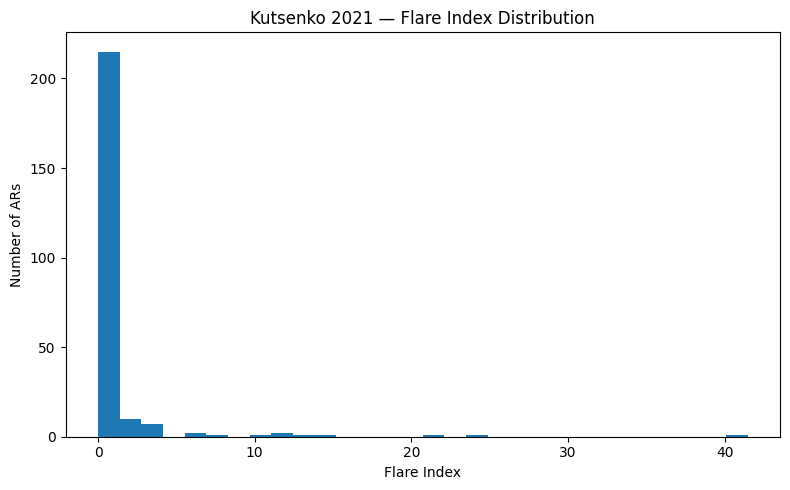

In [56]:
# ============================================================
# FLARE INDEX DISTRIBUTION
# ============================================================

print(
    "Zero-flare ARs:",
    (flare_reg["flare_index"] == 0).sum()
)

print(
    "Non-zero flare ARs:",
    (flare_reg["flare_index"] > 0).sum()
)

print(
    "Maximum flare index:",
    flare_reg["flare_index"].max()
)

plt.figure(figsize=(8, 5))

plt.hist(
    flare_reg["flare_index"].dropna(),
    bins=30
)

plt.xlabel("Flare Index")
plt.ylabel("Number of ARs")
plt.title("Kutsenko 2021 — Flare Index Distribution")

plt.tight_layout()
plt.show()

In [57]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

from scipy.stats import pearsonr, spearmanr

predictors = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "alpha_sat",
    "alpha_mean",
    "alpha_sat_std",
    "alpha_mean_std"
]

correlation_results = []

for feature in predictors:

    temp = flare_reg[
        [
            feature,
            "flare_index"
        ]
    ].dropna()

    if len(temp) < 5:
        continue

    pearson_r, pearson_p = pearsonr(
        temp[feature],
        temp["flare_index"]
    )

    spearman_r, spearman_p = spearmanr(
        temp[feature],
        temp["flare_index"]
    )

    correlation_results.append({
        "Feature": feature,
        "N": len(temp),
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p
    })

correlation_table = pd.DataFrame(
    correlation_results
).sort_values(
    "Spearman_rho",
    ascending=False
)

display(correlation_table)

,Feature,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Phi_max_1e21_Mx,243,0.622015,2.047094e-27,0.547598,2.053289e-20
1,R_av_1e20_Mx_per_h,243,0.474168,5.018535e-15,0.380461,8.656991e-10
5,alpha_mean_std,243,-0.063556,3.238273e-01,0.030489,6.362611e-01
3,alpha_mean,243,-0.108223,9.231995e-02,-0.113144,7.835544e-02
4,alpha_sat_std,243,-0.083434,1.949213e-01,-0.160206,1.239613e-02
2,alpha_sat,243,-0.156164,1.481920e-02,-0.188891,3.116591e-03


In [58]:
# ============================================================
# LOG FLARE INDEX
# ============================================================

flare_reg["log_flare_index"] = np.log10(
    1 + flare_reg["flare_index"]
)

display(
    flare_reg[
        [
            "flare_index",
            "log_flare_index"
        ]
    ].describe()
)

,flare_index,log_flare_index
count,243.000000,243.000000
mean,0.959730,0.119926
std,3.830705,0.274135
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.193050,0.076609
max,41.463600,1.628017


In [59]:
# ============================================================
# CORRELATION WITH LOG(1 + FI)
# ============================================================

log_corr_results = []

for feature in predictors:

    temp = flare_reg[
        [
            feature,
            "log_flare_index"
        ]
    ].dropna()

    if len(temp) < 5:
        continue

    pearson_r, pearson_p = pearsonr(
        temp[feature],
        temp["log_flare_index"]
    )

    spearman_r, spearman_p = spearmanr(
        temp[feature],
        temp["log_flare_index"]
    )

    log_corr_results.append({
        "Feature": feature,
        "N": len(temp),
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p
    })

log_correlation_table = pd.DataFrame(
    log_corr_results
).sort_values(
    "Spearman_rho",
    ascending=False
)

display(log_correlation_table)

,Feature,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Phi_max_1e21_Mx,243,0.708063,2.771390e-38,0.547598,2.053289e-20
1,R_av_1e20_Mx_per_h,243,0.512319,1.157301e-17,0.380461,8.656991e-10
5,alpha_mean_std,243,-0.054124,4.009238e-01,0.030489,6.362611e-01
3,alpha_mean,243,-0.139615,2.956770e-02,-0.113144,7.835544e-02
4,alpha_sat_std,243,-0.111334,8.327906e-02,-0.160206,1.239613e-02
2,alpha_sat,243,-0.208895,1.053704e-03,-0.188891,3.116591e-03


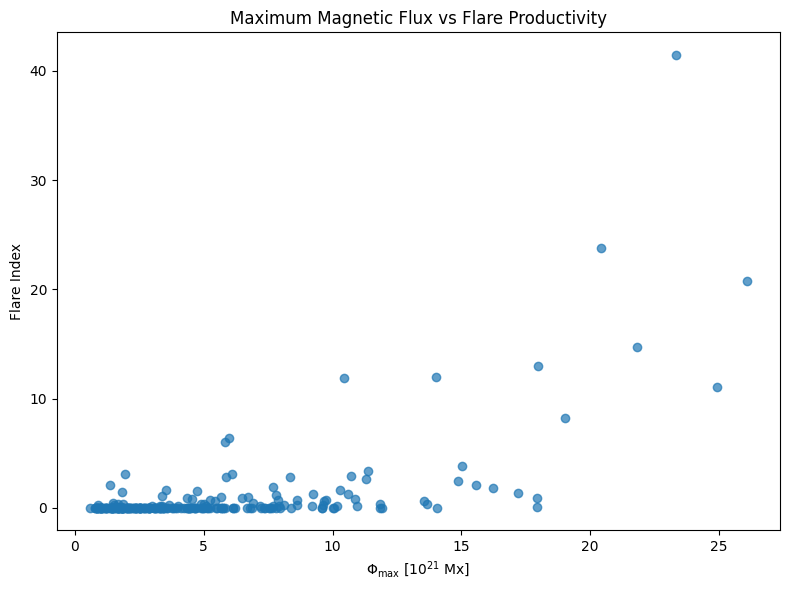

In [60]:
# ============================================================
# PHI MAX VS FLARE INDEX
# ============================================================

plot_phi = flare_reg[
    [
        "Phi_max_1e21_Mx",
        "flare_index"
    ]
].dropna()

plt.figure(figsize=(8, 6))

plt.scatter(
    plot_phi["Phi_max_1e21_Mx"],
    plot_phi["flare_index"],
    alpha=0.7
)

plt.xlabel(
    r"$\Phi_{\max}$ [$10^{21}$ Mx]"
)

plt.ylabel(
    "Flare Index"
)

plt.title(
    "Maximum Magnetic Flux vs Flare Productivity"
)

plt.tight_layout()
plt.show()

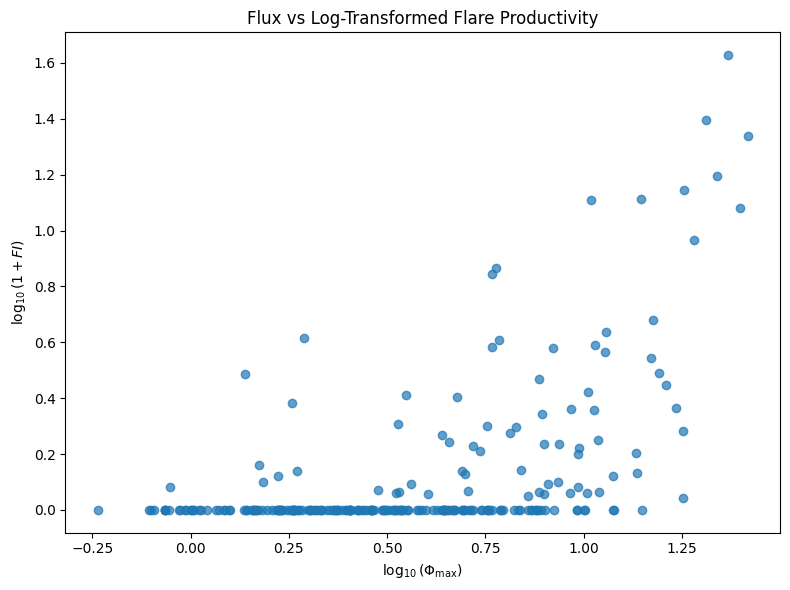

In [61]:
# ============================================================
# LOG PHI VS LOG FLARE INDEX
# ============================================================

plot_phi = flare_reg[
    [
        "Phi_max_1e21_Mx",
        "log_flare_index"
    ]
].dropna()

plot_phi = plot_phi[
    plot_phi["Phi_max_1e21_Mx"] > 0
]

plt.figure(figsize=(8, 6))

plt.scatter(
    np.log10(
        plot_phi["Phi_max_1e21_Mx"]
    ),
    plot_phi["log_flare_index"],
    alpha=0.7
)

plt.xlabel(
    r"$\log_{10}(\Phi_{\max})$"
)

plt.ylabel(
    r"$\log_{10}(1+FI)$"
)

plt.title(
    "Flux vs Log-Transformed Flare Productivity"
)

plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# SIMPLE PHYSICS/STATISTICAL BASELINE
# ============================================================

from sklearn.linear_model import LinearRegression

baseline_data = flare_reg[
    [
        "Phi_max_1e21_Mx",
        "log_flare_index"
    ]
].dropna()

baseline_data = baseline_data[
    baseline_data["Phi_max_1e21_Mx"] > 0
]

X_phi = np.log10(
    baseline_data[
        ["Phi_max_1e21_Mx"]
    ]
)

y_fi = baseline_data[
    "log_flare_index"
]

phi_model = LinearRegression()

phi_model.fit(
    X_phi,
    y_fi
)

phi_pred = phi_model.predict(
    X_phi
)

print(
    "Coefficient:",
    phi_model.coef_[0]
)

print(
    "Intercept:",
    phi_model.intercept_
)

print(
    "R²:",
    r2_score(
        y_fi,
        phi_pred
    )
)

Coefficient: 0.4099643621183239
Intercept: -0.10874386085763345
R²: 0.29386829717939533


In [63]:
# ============================================================
# UNIVARIATE MODELS
# ============================================================

from sklearn.model_selection import KFold, cross_val_score

reg_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

univariate_features = {
    "Phi_max": "Phi_max_1e21_Mx",
    "R_av": "R_av_1e20_Mx_per_h",
    "alpha_sat": "alpha_sat",
    "alpha_mean": "alpha_mean"
}

univariate_results = []

for name, feature in univariate_features.items():

    temp = flare_reg[
        [
            feature,
            "log_flare_index"
        ]
    ].dropna()

    temp = temp[
        temp[feature] > 0
    ]

    X_uni = np.log10(
        temp[
            [feature]
        ]
    )

    y_uni = temp[
        "log_flare_index"
    ]

    scores = cross_val_score(
        LinearRegression(),
        X_uni,
        y_uni,
        cv=reg_cv,
        scoring="r2"
    )

    univariate_results.append({
        "Feature": name,
        "N": len(temp),
        "CV_R2_mean": scores.mean(),
        "CV_R2_std": scores.std()
    })

univariate_table = pd.DataFrame(
    univariate_results
).sort_values(
    "CV_R2_mean",
    ascending=False
)

display(univariate_table)

,Feature,N,CV_R2_mean,CV_R2_std
0,Phi_max,243,0.175753,0.227606
1,R_av,243,0.060193,0.221928
3,alpha_mean,243,-0.024216,0.043671
2,alpha_sat,243,-0.037605,0.139427


In [64]:
# ============================================================
# MULTIVARIATE FLARE MODEL
# ============================================================

FLARE_REG_FEATURES = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "alpha_sat",
    "alpha_mean",
    "alpha_sat_std",
    "alpha_mean_std"
]

reg_model_data = flare_reg[
    FLARE_REG_FEATURES +
    ["log_flare_index"]
].dropna()

X_reg = reg_model_data[
    FLARE_REG_FEATURES
]

y_reg = reg_model_data[
    "log_flare_index"
]

linear_flare = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LinearRegression()
    )
])

scores = cross_validate(
    linear_flare,
    X_reg,
    y_reg,
    cv=reg_cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print(
    "Multivariate linear model"
)

print(
    "R²:",
    scores["test_R2"].mean(),
    "±",
    scores["test_R2"].std()
)

print(
    "MAE:",
    -scores["test_MAE"].mean()
)

print(
    "RMSE:",
    -scores["test_RMSE"].mean()
)

Multivariate linear model
R²: 0.31734825658574484 ± 0.3457626220744922
MAE: 0.13221242541511438
RMSE: 0.20119507233203276


In [65]:
# ============================================================
# RANDOM FOREST — CONTINUOUS FLARE PRODUCTIVITY
# ============================================================

rf_flare_reg = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=1000,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_scores = cross_validate(
    rf_flare_reg,
    X_reg,
    y_reg,
    cv=reg_cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print(
    "Random Forest"
)

print(
    "R²:",
    rf_scores["test_R2"].mean(),
    "±",
    rf_scores["test_R2"].std()
)

print(
    "MAE:",
    -rf_scores["test_MAE"].mean()
)

print(
    "RMSE:",
    -rf_scores["test_RMSE"].mean()
)

Random Forest
R²: 0.36299118841580713 ± 0.18197433863039686
MAE: 0.12660170982071778
RMSE: 0.2029530266458704


In [66]:
# ============================================================
# XGBOOST — CONTINUOUS FLARE PRODUCTIVITY
# ============================================================

from xgboost import XGBRegressor

xgb_flare_reg = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "model",
        XGBRegressor(
            n_estimators=500,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.5,
            reg_lambda=2.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    )
])

xgb_scores = cross_validate(
    xgb_flare_reg,
    X_reg,
    y_reg,
    cv=reg_cv,
    scoring={
        "R2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print(
    "XGBoost"
)

print(
    "R²:",
    xgb_scores["test_R2"].mean(),
    "±",
    xgb_scores["test_R2"].std()
)

print(
    "MAE:",
    -xgb_scores["test_MAE"].mean()
)

print(
    "RMSE:",
    -xgb_scores["test_RMSE"].mean()
)

XGBoost
R²: 0.40510708902615056 ± 0.23893256641074923
MAE: 0.11653442786453483
RMSE: 0.19132673592246957


In [67]:
# ============================================================
# CONTINUOUS FLARE MODEL COMPARISON
# ============================================================

flare_model_comparison = pd.DataFrame([
    {
        "Model": "Phi_max only",
        "CV_R2": univariate_table.iloc[0]["CV_R2_mean"]
    },
    {
        "Model": "Multivariate Linear",
        "CV_R2": scores["test_R2"].mean()
    },
    {
        "Model": "Random Forest",
        "CV_R2": rf_scores["test_R2"].mean()
    },
    {
        "Model": "XGBoost",
        "CV_R2": xgb_scores["test_R2"].mean()
    }
])

display(
    flare_model_comparison.sort_values(
        "CV_R2",
        ascending=False
    )
)

,Model,CV_R2
3,XGBoost,0.405107
2,Random Forest,0.362991
1,Multivariate Linear,0.317348
0,Phi_max only,0.175753


In [68]:
# ============================================================
# XGBOOST FEATURE IMPORTANCE
# ============================================================

# Fit XGBoost on the complete available dataset.
# This is for interpretation only, NOT final performance estimation.

xgb_flare_reg.fit(
    X_reg,
    y_reg
)

xgb_inner = xgb_flare_reg.named_steps["model"]

importance = pd.DataFrame({
    "feature": FLARE_REG_FEATURES,
    "importance": xgb_inner.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(importance)

,feature,importance
0,Phi_max_1e21_Mx,0.471633
1,R_av_1e20_Mx_per_h,0.240777
2,alpha_sat,0.127491
3,alpha_mean,0.068416
5,alpha_mean_std,0.047338
4,alpha_sat_std,0.044344


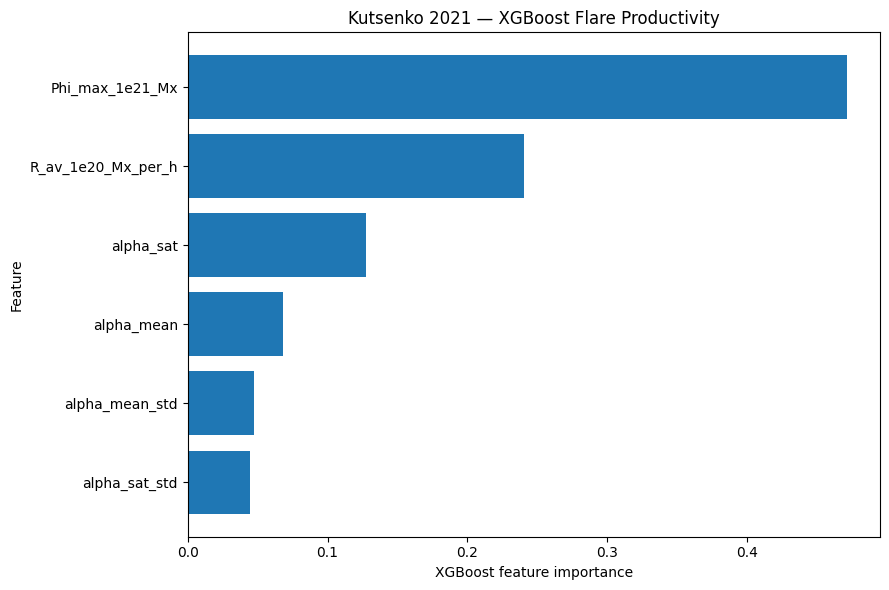

In [69]:
# ============================================================
# FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel("XGBoost feature importance")
plt.ylabel("Feature")

plt.title(
    "Kutsenko 2021 — XGBoost Flare Productivity"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

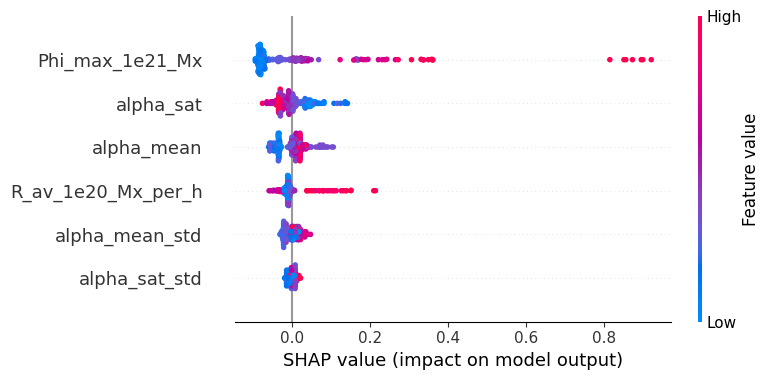

In [70]:
# ============================================================
# SHAP ANALYSIS
# ============================================================

import shap

explainer = shap.TreeExplainer(
    xgb_inner
)

X_shap = X_reg.copy()

shap_values = explainer.shap_values(
    X_shap
)

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=FLARE_REG_FEATURES
)

In [71]:
# ============================================================
# SHAP GLOBAL IMPORTANCE
# ============================================================

shap_importance = pd.DataFrame({
    "feature": FLARE_REG_FEATURES,
    "mean_abs_SHAP": np.abs(
        shap_values
    ).mean(axis=0)
}).sort_values(
    "mean_abs_SHAP",
    ascending=False
)

display(shap_importance)

,feature,mean_abs_SHAP
0,Phi_max_1e21_Mx,0.105927
2,alpha_sat,0.028953
3,alpha_mean,0.025565
1,R_av_1e20_Mx_per_h,0.022639
5,alpha_mean_std,0.014195
4,alpha_sat_std,0.006440


In [72]:
# ============================================================
# FAIR XGBOOST ABLATION
# SAME MODEL + SAME CV + DIFFERENT FEATURES
# ============================================================

XGB_FEATURE_SETS = {

    "Phi_max only": [
        "Phi_max_1e21_Mx"
    ],

    "R_av only": [
        "R_av_1e20_Mx_per_h"
    ],

    "Phi_max + R_av": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h"
    ],

    "Phi + R_av + alpha": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean"
    ],

    "All features": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean",
        "alpha_sat_std",
        "alpha_mean_std"
    ]
}


fair_xgb_results = []

for name, features in XGB_FEATURE_SETS.items():

    X_tmp = flare_reg[
        features
    ]

    y_tmp = flare_reg[
        "log_flare_index"
    ]

    valid = (
        y_tmp.notna()
    )

    X_tmp = X_tmp.loc[valid]
    y_tmp = y_tmp.loc[valid]

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "model",
            XGBRegressor(
                n_estimators=500,
                max_depth=2,
                learning_rate=0.03,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.5,
                reg_lambda=2.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    scores = cross_validate(
        model,
        X_tmp,
        y_tmp,
        cv=reg_cv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    fair_xgb_results.append({
        "Model": name,
        "N_features": len(features),
        "CV_R2": scores[
            "test_R2"
        ].mean(),
        "CV_R2_std": scores[
            "test_R2"
        ].std(),
        "CV_MAE": -scores[
            "test_MAE"
        ].mean(),
        "CV_RMSE": -scores[
            "test_RMSE"
        ].mean()
    })


fair_xgb_table = pd.DataFrame(
    fair_xgb_results
).sort_values(
    "CV_R2",
    ascending=False
)

display(
    fair_xgb_table
)

,Model,N_features,CV_R2,CV_R2_std,CV_MAE,CV_RMSE
0,Phi_max only,1,0.543534,0.062342,0.102843,0.177074
2,Phi_max + R_av,2,0.441793,0.143321,0.113394,0.191544
4,All features,6,0.405107,0.238933,0.116534,0.191327
3,Phi + R_av + alpha,4,0.399921,0.232429,0.113951,0.192623
1,R_av only,1,0.057356,0.183377,0.151392,0.250825


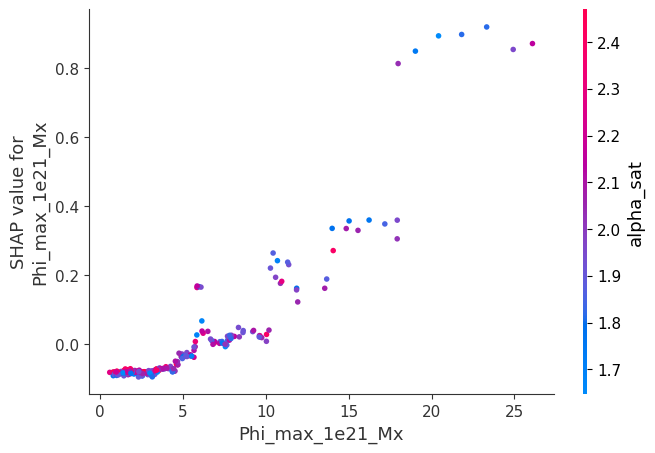

In [73]:
# ============================================================
# SHAP DEPENDENCE — PHI
# ============================================================

shap.dependence_plot(
    "Phi_max_1e21_Mx",
    shap_values,
    X_shap,
    interaction_index="auto"
)

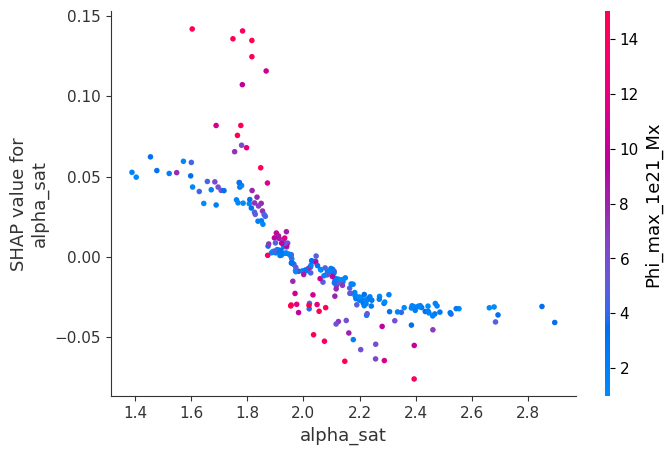

In [74]:
# ============================================================
# SHAP DEPENDENCE — ALPHA SATURATION
# ============================================================

shap.dependence_plot(
    "alpha_sat",
    shap_values,
    X_shap,
    interaction_index="auto"
)

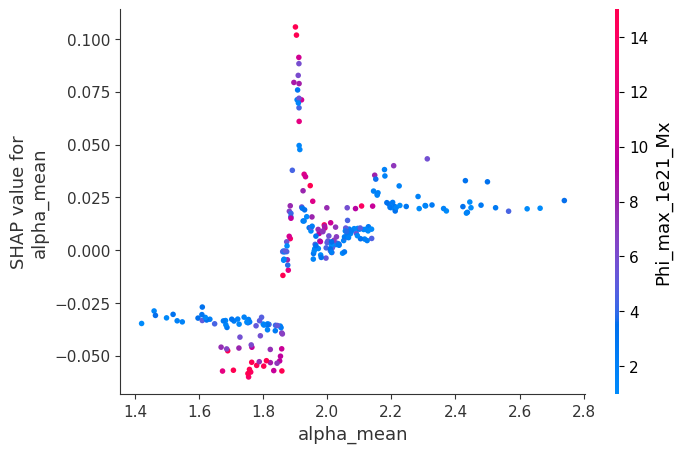

In [75]:
# ============================================================
# SHAP DEPENDENCE — ALPHA MEAN
# ============================================================

shap.dependence_plot(
    "alpha_mean",
    shap_values,
    X_shap,
    interaction_index="auto"
)

In [76]:
# ============================================================
# PHI MAX vs EMERGENCE RATE
# ============================================================

temp = flare_reg[
    [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h"
    ]
].dropna()

temp = temp[
    (temp["Phi_max_1e21_Mx"] > 0) &
    (temp["R_av_1e20_Mx_per_h"] > 0)
]

pearson = pearsonr(
    temp["Phi_max_1e21_Mx"],
    temp["R_av_1e20_Mx_per_h"]
)

spearman = spearmanr(
    temp["Phi_max_1e21_Mx"],
    temp["R_av_1e20_Mx_per_h"]
)

print(
    "Pearson r:",
    pearson[0]
)

print(
    "Spearman rho:",
    spearman[0]
)

Pearson r: 0.7013553683555765
Spearman rho: 0.6721436956983223


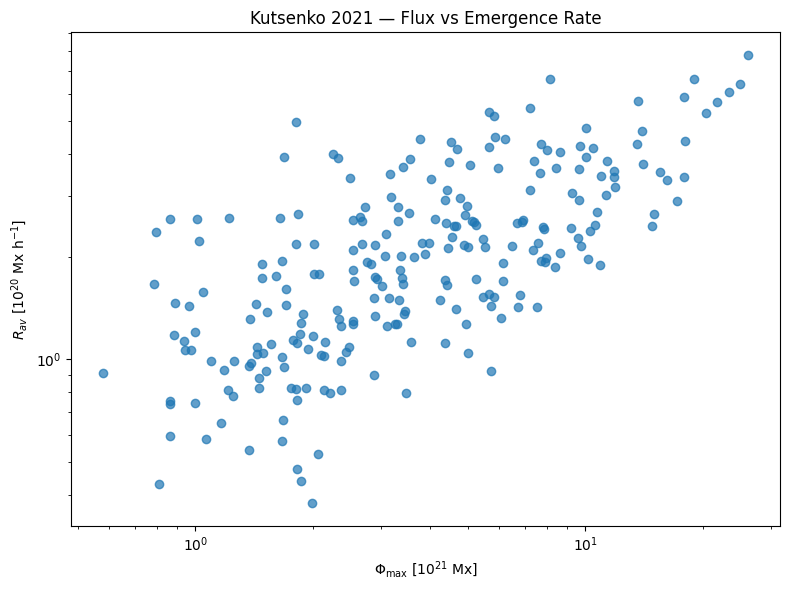

In [77]:
plt.figure(figsize=(8, 6))

plt.scatter(
    temp["Phi_max_1e21_Mx"],
    temp["R_av_1e20_Mx_per_h"],
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    r"$\Phi_{\max}$ [$10^{21}$ Mx]"
)

plt.ylabel(
    r"$R_{av}$ [$10^{20}$ Mx h$^{-1}$]"
)

plt.title(
    "Kutsenko 2021 — Flux vs Emergence Rate"
)

plt.tight_layout()
plt.show()

In [78]:
# ============================================================
# FEATURE CORRELATION
# ============================================================

corr_features = [
    "Phi_max_1e21_Mx",
    "R_av_1e20_Mx_per_h",
    "alpha_sat",
    "alpha_mean",
    "alpha_sat_std",
    "alpha_mean_std"
]

display(
    flare_reg[
        corr_features
    ].corr(
        method="spearman"
    )
)

,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,alpha_sat,alpha_mean,alpha_sat_std,alpha_mean_std
Phi_max_1e21_Mx,1.000000,0.672144,-0.237331,-0.245485,-0.258428,0.049919
R_av_1e20_Mx_per_h,0.672144,1.000000,-0.078246,0.076254,-0.211416,-0.280642
alpha_sat,-0.237331,-0.078246,1.000000,0.682734,0.027834,-0.087353
alpha_mean,-0.245485,0.076254,0.682734,1.000000,0.059908,-0.300884
alpha_sat_std,-0.258428,-0.211416,0.027834,0.059908,1.000000,-0.004162
alpha_mean_std,0.049919,-0.280642,-0.087353,-0.300884,-0.004162,1.000000


In [79]:
# ============================================================
# OUT-OF-FOLD PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold

perm_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

perm_results = []

for train_idx, test_idx in perm_cv.split(X_reg):

    X_train = X_reg.iloc[train_idx]
    X_test = X_reg.iloc[test_idx]

    y_train = y_reg.iloc[train_idx]
    y_test = y_reg.iloc[test_idx]

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                max_depth=2,
                learning_rate=0.03,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.5,
                reg_lambda=2.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(
        X_train,
        y_train
    )

    perm = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="r2",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    for feature, mean, std in zip(
        X_reg.columns,
        perm.importances_mean,
        perm.importances_std
    ):

        perm_results.append({
            "feature": feature,
            "importance": mean,
            "std": std
        })

permutation_table = (
    pd.DataFrame(perm_results)
    .groupby("feature")
    .agg(
        mean_importance=("importance", "mean"),
        std_importance=("importance", "std")
    )
    .sort_values(
        "mean_importance",
        ascending=False
    )
)

display(permutation_table)

,mean_importance,std_importance
feature,,
Phi_max_1e21_Mx,0.760692,0.155417
alpha_mean,0.029775,0.048483
alpha_sat,0.027016,0.031302
alpha_mean_std,0.005788,0.011729
R_av_1e20_Mx_per_h,-0.011643,0.100036
alpha_sat_std,-0.016148,0.023891


In [80]:
# ============================================================
# SHAP INTERACTION STRENGTH
# ============================================================

interaction_values = explainer.shap_interaction_values(
    X_shap
)

interaction_values = np.asarray(
    interaction_values
)

feature_names = list(
    X_shap.columns
)

interaction_strength = np.abs(
    interaction_values
).mean(axis=0)

interaction_table = []

for i in range(
    len(feature_names)
):

    for j in range(
        i + 1,
        len(feature_names)
    ):

        interaction_table.append({
            "feature_1": feature_names[i],
            "feature_2": feature_names[j],
            "mean_abs_interaction":
                interaction_strength[i, j]
        })

interaction_table = pd.DataFrame(
    interaction_table
).sort_values(
    "mean_abs_interaction",
    ascending=False
)

display(
    interaction_table.head(15)
)

,feature_1,feature_2,mean_abs_interaction
5,R_av_1e20_Mx_per_h,alpha_sat,0.006008
1,Phi_max_1e21_Mx,alpha_sat,0.005945
2,Phi_max_1e21_Mx,alpha_mean,0.004395
0,Phi_max_1e21_Mx,R_av_1e20_Mx_per_h,0.003366
6,R_av_1e20_Mx_per_h,alpha_mean,0.001619
13,alpha_mean,alpha_mean_std,0.001537
4,Phi_max_1e21_Mx,alpha_mean_std,0.001452
9,alpha_sat,alpha_mean,0.001010
14,alpha_sat_std,alpha_mean_std,0.000864
11,alpha_sat,alpha_mean_std,0.000782


In [81]:
# ============================================================
# FAIR XGBOOST ABLATION
# ============================================================

XGB_FEATURE_SETS = {

    "Phi_max only": [
        "Phi_max_1e21_Mx"
    ],

    "R_av only": [
        "R_av_1e20_Mx_per_h"
    ],

    "Phi_max + R_av": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h"
    ],

    "Phi + R_av + alpha": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean"
    ],

    "All features": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean",
        "alpha_sat_std",
        "alpha_mean_std"
    ]
}

fair_xgb_results = []

for name, features in XGB_FEATURE_SETS.items():

    data = flare_reg[
        features + ["log_flare_index"]
    ].replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna(
        subset=["log_flare_index"]
    )

    X_tmp = data[features]
    y_tmp = data["log_flare_index"]

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                max_depth=2,
                learning_rate=0.03,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.5,
                reg_lambda=2.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    scores = cross_validate(
        model,
        X_tmp,
        y_tmp,
        cv=reg_cv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    fair_xgb_results.append({
        "Model": name,
        "N_features": len(features),
        "CV_R2": scores["test_R2"].mean(),
        "CV_R2_std": scores["test_R2"].std(),
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_RMSE": -scores["test_RMSE"].mean()
    })

fair_xgb_table = pd.DataFrame(
    fair_xgb_results
).sort_values(
    "CV_R2",
    ascending=False
)

display(fair_xgb_table)

,Model,N_features,CV_R2,CV_R2_std,CV_MAE,CV_RMSE
0,Phi_max only,1,0.543534,0.062342,0.102843,0.177074
2,Phi_max + R_av,2,0.441793,0.143321,0.113394,0.191544
4,All features,6,0.405107,0.238933,0.116534,0.191327
3,Phi + R_av + alpha,4,0.399921,0.232429,0.113951,0.192623
1,R_av only,1,0.057356,0.183377,0.151392,0.250825


In [82]:
# ============================================================
# REPEATED CV — PHI MAX VS ALL FEATURES
# ============================================================

from sklearn.model_selection import RepeatedKFold

repeated_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=42
)

REPEATED_FEATURE_SETS = {

    "Phi_max only": [
        "Phi_max_1e21_Mx"
    ],

    "Phi_max + R_av": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h"
    ],

    "All features": [
        "Phi_max_1e21_Mx",
        "R_av_1e20_Mx_per_h",
        "alpha_sat",
        "alpha_mean",
        "alpha_sat_std",
        "alpha_mean_std"
    ]
}

repeated_results = []

for name, features in REPEATED_FEATURE_SETS.items():

    data = flare_reg[
        features + ["log_flare_index"]
    ].replace(
        [np.inf, -np.inf],
        np.nan
    )

    data = data.dropna(
        subset=["log_flare_index"]
    )

    X_tmp = data[features]
    y_tmp = data["log_flare_index"]

    model = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                max_depth=2,
                learning_rate=0.03,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.5,
                reg_lambda=2.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    scores = cross_val_score(
        model,
        X_tmp,
        y_tmp,
        cv=repeated_cv,
        scoring="r2",
        n_jobs=-1
    )

    repeated_results.append({
        "Model": name,
        "Mean_R2": scores.mean(),
        "Std_R2": scores.std(),
        "Median_R2": np.median(scores),
        "Min_R2": scores.min(),
        "Max_R2": scores.max(),
        "N_folds": len(scores)
    })

repeated_table = pd.DataFrame(
    repeated_results
).sort_values(
    "Mean_R2",
    ascending=False
)

display(repeated_table)

,Model,Mean_R2,Std_R2,Median_R2,Min_R2,Max_R2,N_folds
0,Phi_max only,0.499284,0.231466,0.553795,-0.969091,0.816640,100
1,Phi_max + R_av,0.400925,0.313614,0.474032,-1.467333,0.783536,100
2,All features,0.384298,0.295278,0.466921,-1.205482,0.782816,100


In [83]:
# ============================================================
# FLARE PRODUCTIVITY BY PHI QUARTILE
# ============================================================

phi_analysis = flare_reg[
    [
        "Phi_max_1e21_Mx",
        "flare_index",
        "log_flare_index"
    ]
].dropna()

phi_analysis["Phi_quartile"] = pd.qcut(
    phi_analysis[
        "Phi_max_1e21_Mx"
    ],
    q=4,
    duplicates="drop"
)

quartile_summary = (
    phi_analysis
    .groupby("Phi_quartile", observed=True)
    .agg(
        N=("flare_index", "size"),
        median_phi=("Phi_max_1e21_Mx", "median"),
        median_FI=("flare_index", "median"),
        mean_FI=("flare_index", "mean"),
        productive_fraction=(
            "flare_index",
            lambda x: (x >= 1).mean()
        )
    )
)

display(quartile_summary)

,N,median_phi,median_FI,mean_FI,productive_fraction
Phi_quartile,,,,,
"(0.58, 1.846]",61,1.39420,0.00,0.077434,0.032787
"(1.846, 3.403]",61,2.54090,0.00,0.082220,0.032787
"(3.403, 6.772]",60,4.83055,0.00,0.473495,0.116667
"(6.772, 26.087]",61,10.04380,0.39,3.197798,0.377049


In [84]:
# ============================================================
# PHASE III
# DISCOVER SHARP / EMERGING-AR TIME-SERIES FILES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path("/kaggle/input")

files = []

for p in BASE.rglob("*"):
    if p.is_file():
        files.append(p)

print("=" * 80)
print("FILES AVAILABLE IN KAGGLE INPUT")
print("=" * 80)

for p in files:
    print(p)

FILES AVAILABLE IN KAGGLE INPUT
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2019_2021_common_HARP_index.csv
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2021_243_AR_supplement_available.csv
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2021_243_AR_model_ready.csv
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2019_423_AR_clean.csv


In [85]:
# ============================================================
# TABULAR FILES
# ============================================================

tabular = [
    p for p in files
    if p.suffix.lower() in [
        ".csv",
        ".ods",
        ".xlsx",
        ".xls"
    ]
]

print("\nTABULAR FILES")
print("-" * 80)

for p in tabular:
    print(p)


TABULAR FILES
--------------------------------------------------------------------------------
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2019_2021_common_HARP_index.csv
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2021_243_AR_supplement_available.csv
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2021_243_AR_model_ready.csv
/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2019_423_AR_clean.csv


In [86]:
# ============================================================
# CSV STRUCTURE AUDIT
# ============================================================

for path in tabular:

    if path.suffix.lower() != ".csv":
        continue

    print("\n" + "=" * 80)
    print(path)
    print("=" * 80)

    try:

        temp = pd.read_csv(
            path,
            nrows=5
        )

        print("Columns:")
        print(
            list(temp.columns)
        )

        print(
            "Sample shape:",
            temp.shape
        )

    except Exception as e:

        print(
            "Could not read:",
            e
        )


/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2019_2021_common_HARP_index.csv
Columns:
['HARP', 'n_rows_2019', 'n_rows_2021', '2019_row_indices', '2021_row_indices', 'match_type']
Sample shape: (5, 6)

/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2021_243_AR_supplement_available.csv
Columns:
['HARP', 'emergence_onset', 'power_index_saturation_time', 'peak_flux_time', 'alpha_sat', 'alpha_sat_std', 'alpha_mean', 'alpha_mean_std', 'Phi_max_1e21_Mx', 'Phi_max_uncertainty_1e21_Mx', 'R_av_1e20_Mx_per_h', 'R_av_uncertainty_1e20_Mx_per_h', 'flare_index']
Sample shape: (5, 13)

/kaggle/input/datasets/sj3267/kutsenko/KUTSENKO_2021_243_AR_model_ready.csv
Columns:
['HARP', 'emergence_onset', 'power_index_saturation_time', 'peak_flux_time', 'alpha_sat', 'alpha_sat_std', 'alpha_mean', 'alpha_mean_std', 'Phi_max_1e21_Mx', 'Phi_max_uncertainty_1e21_Mx', 'R_av_1e20_Mx_per_h', 'R_av_uncertainty_1e20_Mx_per_h', 'flare_index', 'flare_productive_FI_ge_1', 'log10_Phi_max', 'log10_R_av']
Sample shape: 